In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('csv/dataset_completo.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13446 entries, 0 to 13445
Data columns (total 63 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   img_original        13446 non-null  object 
 1   img_recodificada    13446 non-null  object 
 2   metodo              13446 non-null  object 
 3   formato             13446 non-null  object 
 4   calidad             13446 non-null  int64  
 5   orig_rango          13446 non-null  float64
 6   orig_std            13446 non-null  float64
 7   orig_michelson      13446 non-null  float64
 8   orig_hf             13446 non-null  float64
 9   orig_lf             13446 non-null  float64
 10  orig_hlfr           13446 non-null  float64
 11  orig_edges_s1       13446 non-null  float64
 12  orig_edges_s2       13446 non-null  float64
 13  orig_edges_s3       13446 non-null  float64
 14  orig_grad_mean      13446 non-null  float64
 15  orig_grad_std       13446 non-null  float64
 16  orig

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use("dark_background")

print("Shape:", df.shape)
df.head()

Shape: (13446, 63)


,img_original,img_recodificada,metodo,formato,calidad,orig_rango,orig_std,orig_michelson,orig_hf,orig_lf,...,comp_hist_std,comp_hist_mean,comp_hist_min,comp_hist_max,comp_hist_skew,comp_hist_kurt,ms_ssim,lpips_raw,lpips_norm,combinado
0,imagenes\jpg\COCO_test2014_000000000080.jpg,imagenes/pillow/webp/COCO_test2014_00000000008...,pillow,webp,10,0.99689,0.219220,0.878967,127894710.0,1.477603e+10,...,0.002955,0.003906,0.000004,0.009423,2.822142e-09,1.311509e-10,0.949915,0.172519,0.852865,0.901390
1,imagenes\jpg\COCO_test2014_000000000080.jpg,imagenes/pillow/webp/COCO_test2014_00000000008...,pillow,webp,90,0.99689,0.219220,0.878967,127894710.0,1.477603e+10,...,0.002809,0.003906,0.000000,0.009349,5.895150e-10,1.117986e-10,0.998036,0.007235,0.992817,0.995427
2,imagenes\jpg\COCO_test2014_000000000080.jpg,imagenes/pillow/webp/COCO_test2014_00000000008...,pillow,webp,50,0.99689,0.219220,0.878967,127894710.0,1.477603e+10,...,0.002832,0.003906,0.000004,0.009448,1.038800e-09,1.146488e-10,0.986651,0.055201,0.947686,0.967169
3,imagenes\jpg\COCO_test2014_000000000527.jpg,imagenes/ffmpeg/webp/COCO_test2014_00000000052...,ffmpeg,webp,50,1.00000,0.263755,0.877597,375268830.0,1.261751e+10,...,0.002643,0.003906,0.000443,0.009648,8.261854e-09,8.844339e-11,0.964152,0.107810,0.902682,0.933417
4,imagenes\jpg\COCO_test2014_000000000527.jpg,imagenes/ffmpeg/webp/COCO_test2014_00000000052...,ffmpeg,webp,30,1.00000,0.263755,0.877597,375268830.0,1.261751e+10,...,0.002621,0.003906,0.000451,0.009878,7.666411e-09,8.377743e-11,0.968825,0.086951,0.920004,0.944415


In [6]:
print("Valores nulos:")
print(df.isnull().sum().sum())

print("\nDuplicados:")
print(df.duplicated().sum())

print("\nTipos de datos:")
print(df.dtypes.value_counts())

Valores nulos:
0

Duplicados:
0

Tipos de datos:
float64    52
object     10
int64       1
Name: count, dtype: int64


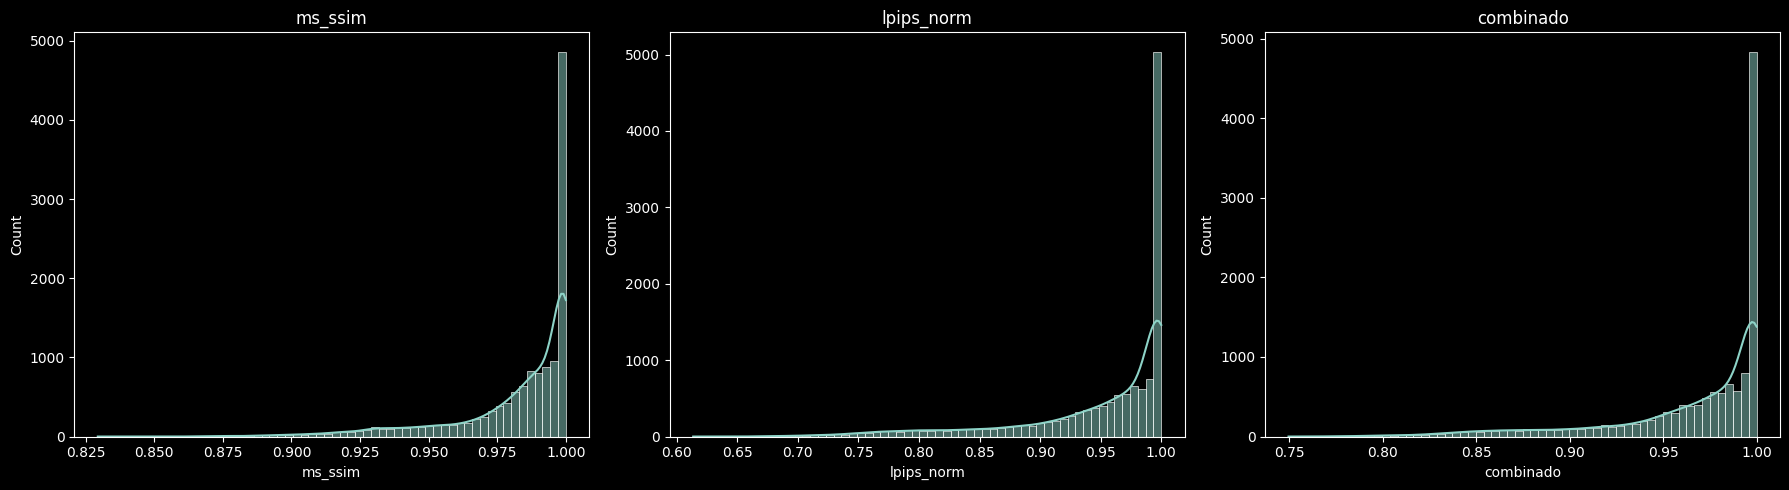

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18,5))

cols = ["ms_ssim", "lpips_norm", "combinado"]

for i, col in enumerate(cols):
    sns.histplot(df[col], bins=60, kde=True, ax=ax[i])
    ax[i].set_title(col)

plt.tight_layout()
plt.show()

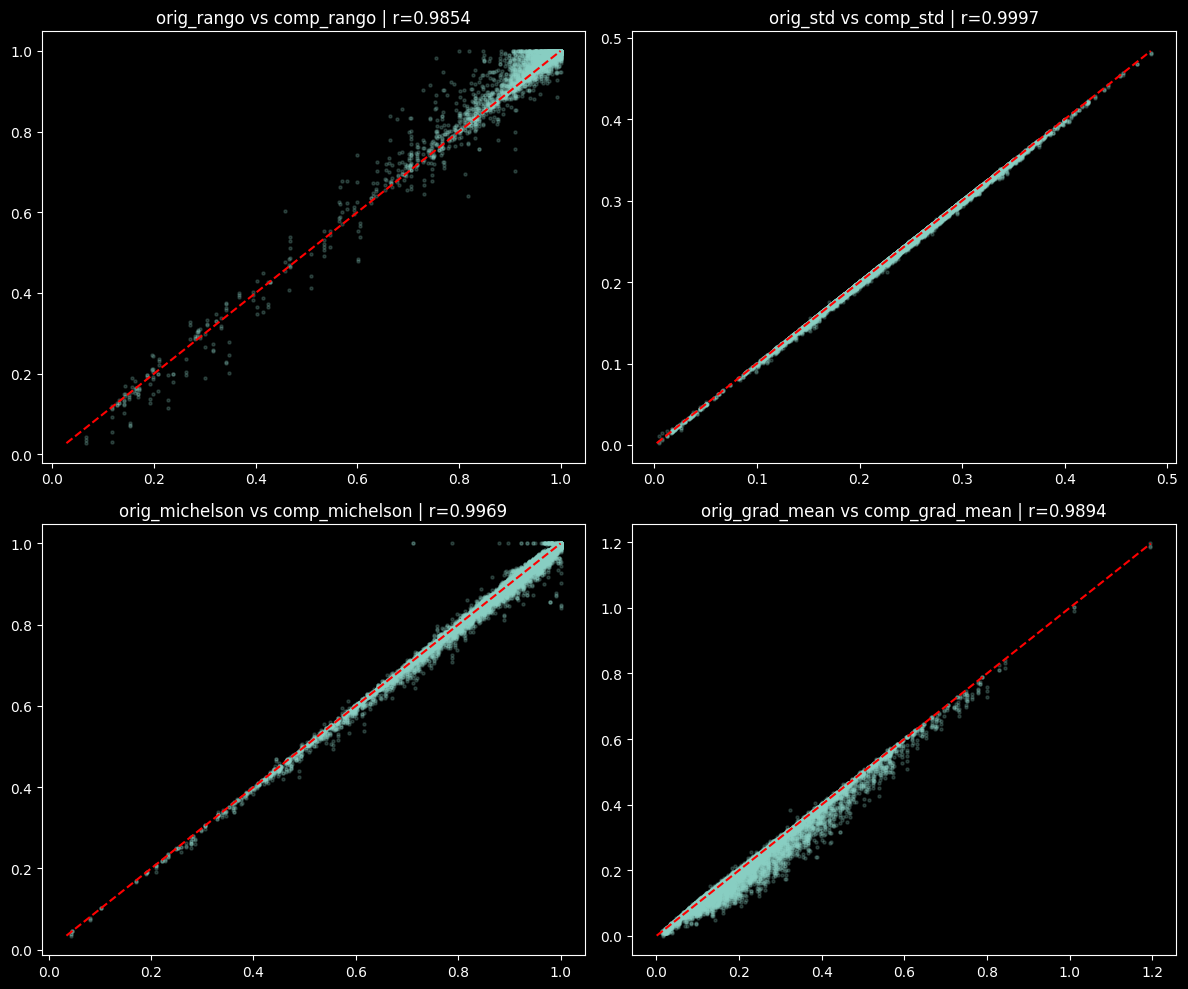

In [8]:
pares = [
    ("orig_rango","comp_rango"),
    ("orig_std","comp_std"),
    ("orig_michelson","comp_michelson"),
    ("orig_grad_mean","comp_grad_mean"),
]

fig, axes = plt.subplots(2,2, figsize=(12,10))

for ax, (o,c) in zip(axes.flat, pares):
    ax.scatter(df[o], df[c], alpha=0.2, s=5)
    
    # línea ideal
    min_v = min(df[o].min(), df[c].min())
    max_v = max(df[o].max(), df[c].max())
    ax.plot([min_v,max_v],[min_v,max_v],'r--')
    
    r,_ = stats.pearsonr(df[o], df[c])
    ax.set_title(f"{o} vs {c} | r={r:.4f}")

plt.tight_layout()
plt.show()

In [9]:
cols = ["ms_ssim", "lpips_norm", "combinado"]

for col in cols:
    r, _ = stats.pearsonr(df["calidad"], df[col])
    print(f"{col} vs calidad: r = {r:.4f}")

ms_ssim vs calidad: r = 0.3229
lpips_norm vs calidad: r = 0.3407
combinado vs calidad: r = 0.3399


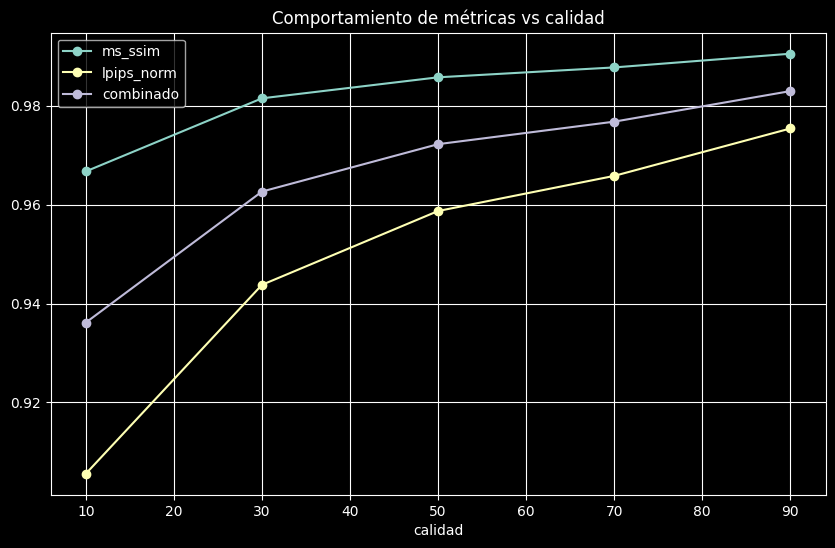

In [10]:
means = df.groupby("calidad")[["ms_ssim","lpips_norm","combinado"]].mean()

means.plot(marker="o", figsize=(10,6))
plt.title("Comportamiento de métricas vs calidad")
plt.grid()
plt.show()

In [11]:
df["z_ssim"] = np.abs(stats.zscore(df["ms_ssim"]))
df["z_lpips"] = np.abs(stats.zscore(df["lpips_norm"]))
df["z_comb"] = np.abs(stats.zscore(df["combinado"]))

df["anomalia"] = (df["z_ssim"]>3) | (df["z_lpips"]>3) | (df["z_comb"]>3)

print("Anomalías:", df["anomalia"].sum())
print("Porcentaje:", df["anomalia"].mean()*100)

Anomalías: 357
Porcentaje: 2.6550647032574743


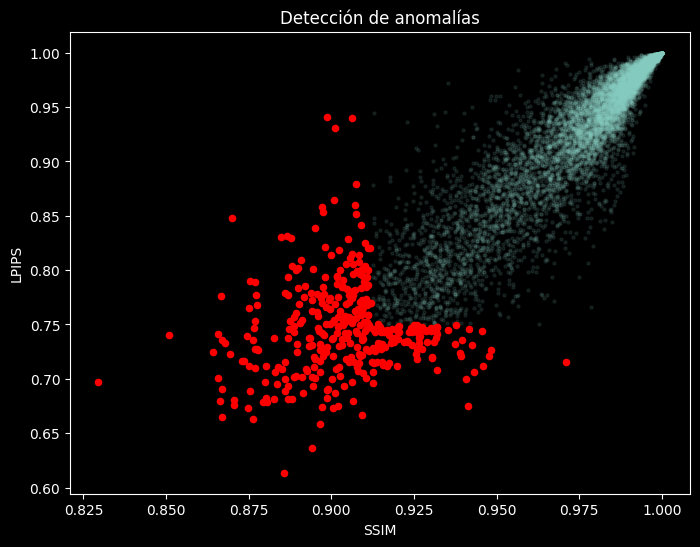

In [12]:
plt.figure(figsize=(8,6))

normal = df[~df["anomalia"]]
anom = df[df["anomalia"]]

plt.scatter(normal["ms_ssim"], normal["lpips_norm"], alpha=0.1, s=5)
plt.scatter(anom["ms_ssim"], anom["lpips_norm"], color="red", s=20)

plt.xlabel("SSIM")
plt.ylabel("LPIPS")
plt.title("Detección de anomalías")
plt.show()

In [13]:
# diferencia entre original y recodificada
diff = df["orig_rango"] - df["comp_rango"]

t_stat, p_val = stats.ttest_rel(df["orig_rango"], df["comp_rango"])

print("T-test:")
print("t =", t_stat)
print("p =", p_val)


T-test:
t = -22.707139939970975
p = 4.813392631088513e-112


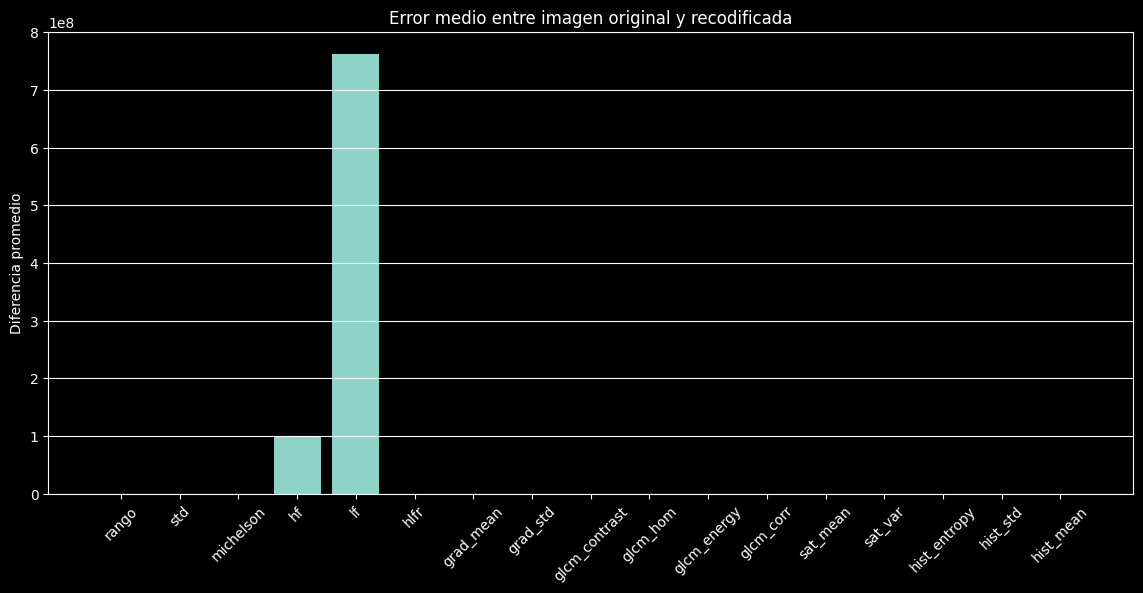

In [14]:
# Diferencias absolutas
features = [
    "rango", "std", "michelson", "hf", "lf", "hlfr",
    "grad_mean", "grad_std",
    "glcm_contrast", "glcm_hom", "glcm_energy", "glcm_corr",
    "sat_mean", "sat_var",
    "hist_entropy", "hist_std", "hist_mean"
]

import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

diff_means = []

for f in features:
    diff = abs(df[f"orig_{f}"] - df[f"comp_{f}"])
    diff_means.append(diff.mean())

plt.bar(features, diff_means)
plt.xticks(rotation=45)
plt.title("Error medio entre imagen original y recodificada")
plt.ylabel("Diferencia promedio")
plt.grid(axis='y')
plt.show()

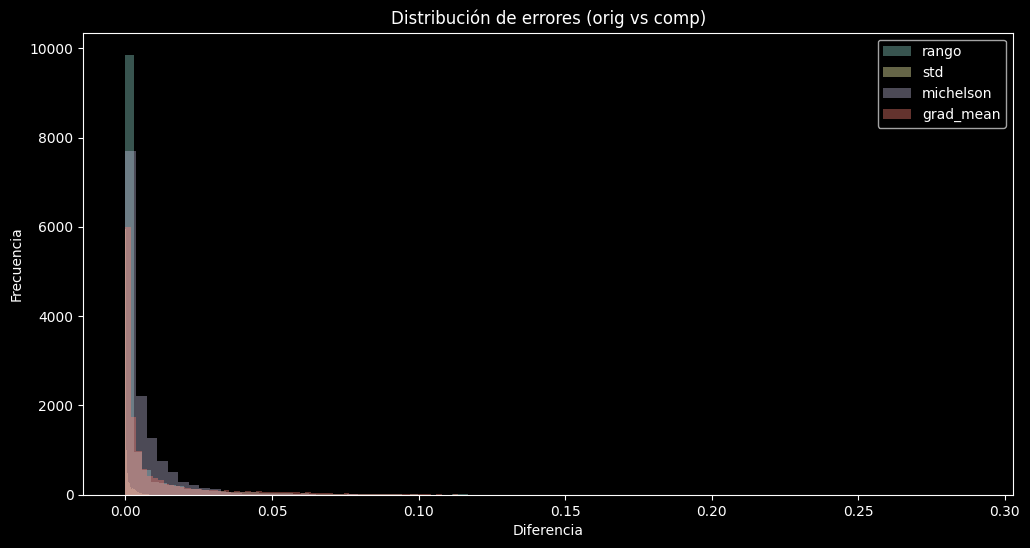

In [15]:
plt.figure(figsize=(12,6))

for f in ["rango", "std", "michelson", "grad_mean"]:
    diff = abs(df[f"orig_{f}"] - df[f"comp_{f}"])
    plt.hist(diff, bins=80, alpha=0.4, label=f)

plt.legend()
plt.title("Distribución de errores (orig vs comp)")
plt.xlabel("Diferencia")
plt.ylabel("Frecuencia")
plt.show()

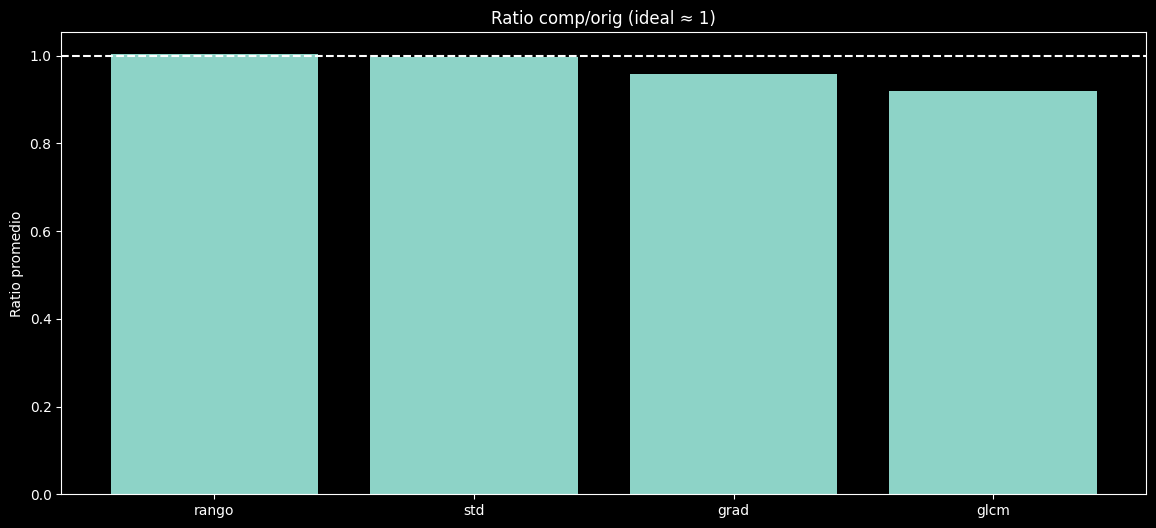

In [16]:
plt.figure(figsize=(14,6))

ratios = []

for f in ["rango", "std", "grad_mean", "glcm_contrast"]:
    ratio = df[f"comp_{f}"] / (df[f"orig_{f}"] + 1e-6)
    ratios.append(ratio.mean())

plt.bar(["rango","std","grad","glcm"], ratios)
plt.axhline(1, linestyle="--")
plt.title("Ratio comp/orig (ideal ≈ 1)")
plt.ylabel("Ratio promedio")
plt.show()

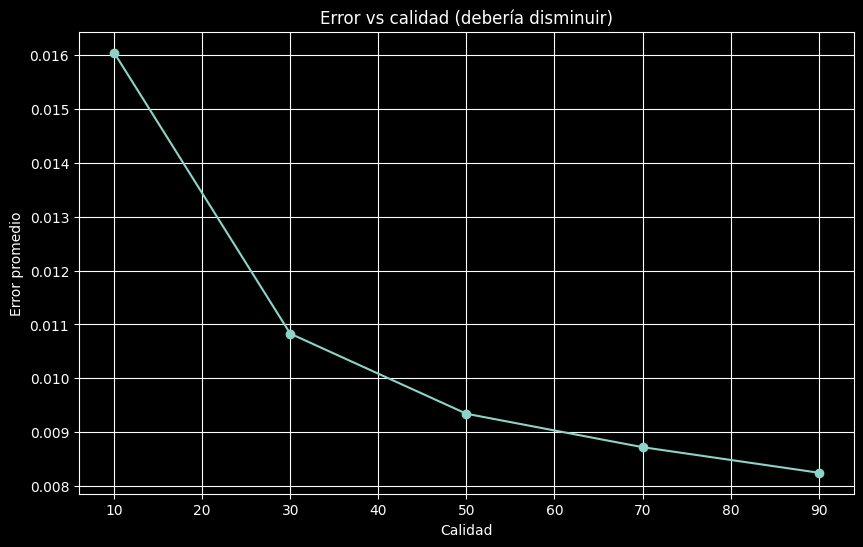

In [17]:
plt.figure(figsize=(10,6))

calidades = sorted(df["calidad"].unique())

errors = []

for q in calidades:
    subset = df[df["calidad"] == q]
    err = abs(subset["orig_grad_mean"] - subset["comp_grad_mean"]).mean()
    errors.append(err)

plt.plot(calidades, errors, marker="o")
plt.title("Error vs calidad (debería disminuir)")
plt.xlabel("Calidad")
plt.ylabel("Error promedio")
plt.grid()
plt.show()

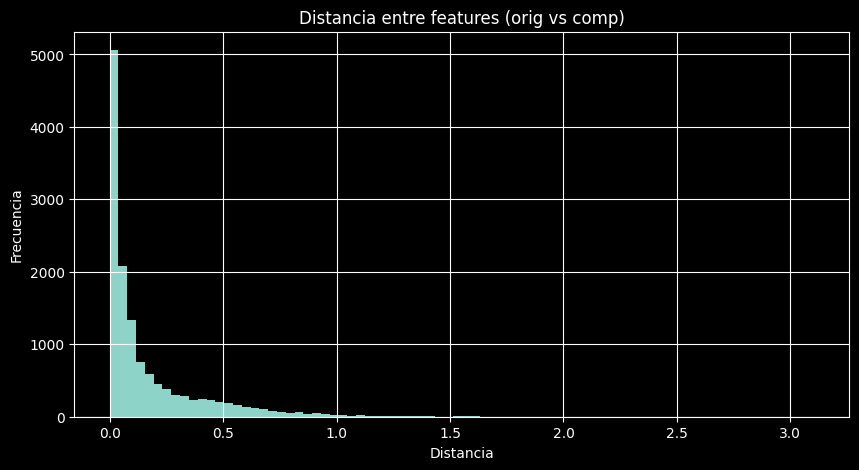

In [23]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import euclidean
import matplotlib.pyplot as plt

features_use = ["rango","std","michelson","grad_mean","glcm_contrast"]

# Extraer
orig = df[[f"orig_{f}" for f in features_use]].copy()
comp = df[[f"comp_{f}" for f in features_use]].copy()

# 🔥 CLAVE: igualar nombres de columnas
comp.columns = orig.columns

# Escalado
scaler = StandardScaler()

# 🔥 Mejor práctica: usar ambos
combined = pd.concat([orig, comp])
scaler.fit(combined)

orig_scaled = scaler.transform(orig)
comp_scaled = scaler.transform(comp)

# Distancias
distancias = [euclidean(o, c) for o, c in zip(orig_scaled, comp_scaled)]

df["distancia_feat"] = distancias

# Gráfica
plt.figure(figsize=(10,5))
plt.hist(distancias, bins=80)
plt.title("Distancia entre features (orig vs comp)")
plt.xlabel("Distancia")
plt.ylabel("Frecuencia")
plt.grid()
plt.show()

In [24]:
threshold = df["distancia_feat"].mean() + 3 * df["distancia_feat"].std()

df["posible_error"] = df["distancia_feat"] > threshold

print("Posibles errores:", df["posible_error"].sum())

Posibles errores: 261


In [25]:
peores = df.sort_values("distancia_feat", ascending=False).head(10)

print(peores[["img_original", "img_recodificada", "distancia_feat"]])

                         img_original  \
11192  imagenes\png\Cats_Test2263.png   
10741  imagenes\png\Cats_Test1061.png   
12550  imagenes\png\Image_194 (9).png   
9977         imagenes\png\483 (3).png   
10219        imagenes\png\607 (2).png   
9602         imagenes\png\142 (4).png   
9600         imagenes\png\142 (4).png   
10778   imagenes\png\Cats_Test118.png   
10628            imagenes\png\890.png   
9553         imagenes\png\116 (4).png   

                                        img_recodificada  distancia_feat  
11192   imagenes/pillow/jpg/Cats_Test2263_pillow_q10.jpg        3.105027  
10741  imagenes/imagemagick/jpg/Cats_Test1061_imagema...        3.006028  
12550  imagenes/ffmpeg/webp/Image_194 (9)_ffmpeg_q90....        2.551367  
9977   imagenes/imagemagick/jpg/483 (3)_imagemagick_q...        2.293081  
10219  imagenes/imagemagick/jpg/607 (2)_imagemagick_q...        2.230991  
9602          imagenes/pillow/jpg/142 (4)_pillow_q30.jpg        2.154725  
9600          imagenes/

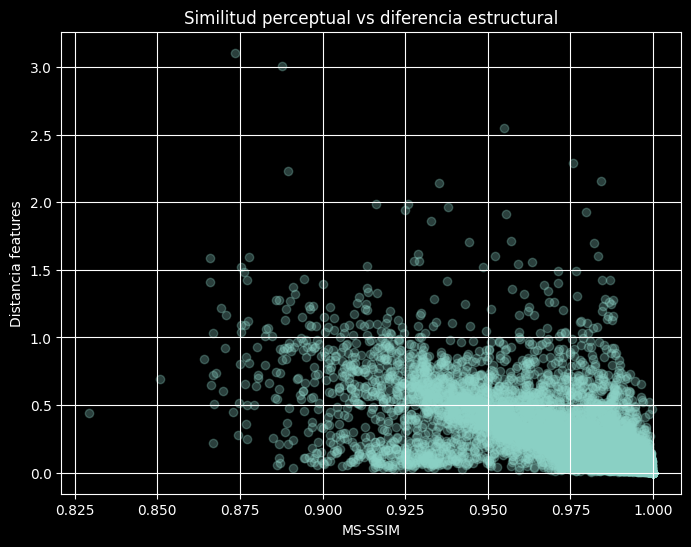

In [26]:
plt.figure(figsize=(8,6))

plt.scatter(df["ms_ssim"], df["distancia_feat"], alpha=0.3)

plt.xlabel("MS-SSIM")
plt.ylabel("Distancia features")
plt.title("Similitud perceptual vs diferencia estructural")

plt.grid()
plt.show()

In [27]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import euclidean

features_use = ["rango","std","michelson","grad_mean","glcm_contrast"]

orig = df[[f"orig_{f}" for f in features_use]].copy()
comp = df[[f"comp_{f}" for f in features_use]].copy()

comp.columns = orig.columns

scaler = StandardScaler()
scaler.fit(pd.concat([orig, comp]))

orig_scaled = scaler.transform(orig)
comp_scaled = scaler.transform(comp)

df["distancia_feat"] = [euclidean(o, c) for o, c in zip(orig_scaled, comp_scaled)]

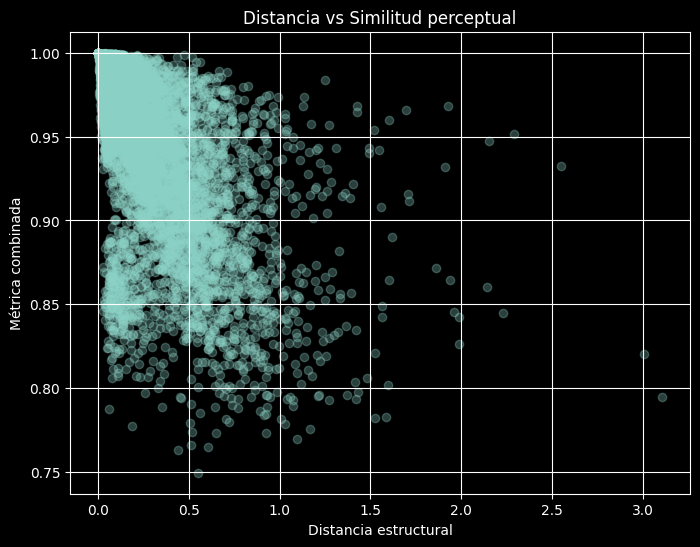

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(df["distancia_feat"], df["combinado"], alpha=0.3)

plt.xlabel("Distancia estructural")
plt.ylabel("Métrica combinada")
plt.title("Distancia vs Similitud perceptual")

plt.grid()
plt.show()

In [29]:
from scipy.stats import pearsonr

r, _ = pearsonr(df["distancia_feat"], df["combinado"])

print(f"Correlación distancia vs combinado: {r:.4f}")

Correlación distancia vs combinado: -0.6969


In [30]:
threshold_dist = df["distancia_feat"].mean() + 3 * df["distancia_feat"].std()
threshold_comb = 0.5  # puedes ajustar

df["posible_error"] = (
    (df["distancia_feat"] > threshold_dist) &
    (df["combinado"] < threshold_comb)
)

print("Posibles errores:", df["posible_error"].sum())

Posibles errores: 0


In [31]:
df[df["posible_error"]][[
    "img_original",
    "img_recodificada",
    "distancia_feat",
    "combinado"
]].head(10)

,img_original,img_recodificada,distancia_feat,combinado


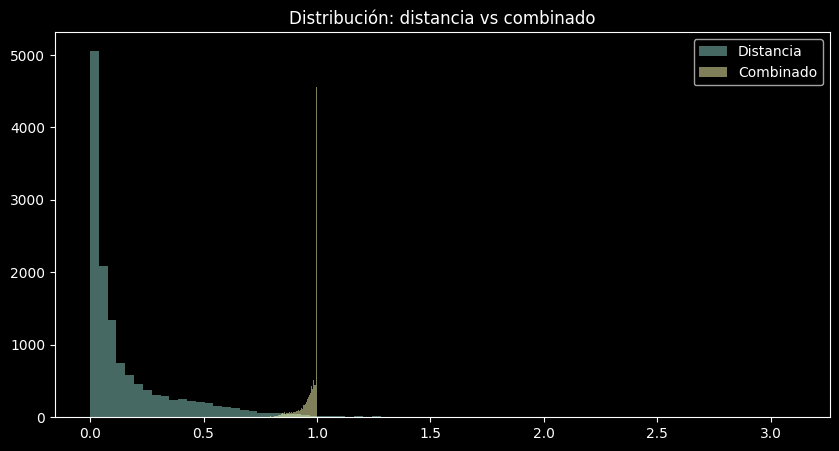

In [32]:
plt.figure(figsize=(10,5))

plt.hist(df["distancia_feat"], bins=80, alpha=0.5, label="Distancia")
plt.hist(df["combinado"], bins=80, alpha=0.5, label="Combinado")

plt.legend()
plt.title("Distribución: distancia vs combinado")
plt.show()